# Lecture 8. Newton and quasi-Newton methods

**Convex optimization, Fall 2026**

- Lectures 6 and 7 moved with gradients only. The model behind a gradient step of length $\eta$ replaces the Hessian by $(1/\eta)\mathbf{I}$. The condition number $\kappa$ is the price of that replacement.
- Newton's method puts the Hessian back into the model. Locally, $\kappa$ leaves the rate. It remains in the cost of each iteration, and in the size of the neighborhood where the rate holds.
- Forming and factoring a dense Hessian is $\Theta(n^3)$ after the derivatives are available, and impossible at the dimensions where a gradient is still cheap. Quasi-Newton methods keep a matrix that agrees with the Hessian along the step just taken, and they update that matrix from the two gradients at its ends.
- Notation is unchanged. $\|\cdot\|$ is the Euclidean norm, $f'$ is the gradient, $f''$ is the Hessian, $f^\star$ is the optimal value. A vector step is $\mathbf{d}$, and $\mathbf{x}^+$ means the next iterate.


## Plan

1. Newton's method from the quadratic model, and the same iteration as a root finder
2. What "local" means, on a function where one step jumps
3. Quadratic convergence
4. Damped Newton: a line search, and what it changes in the rate
5. Inexact Newton: conjugate gradients inside the Newton step
6. The secant equation, BFGS, and the Barzilai–Borwein step
7. How the BFGS update is checked and applied
8. L-BFGS: the stored pairs and the two-loop product
9. What is gained, and where these methods stop

- The notebook uses NumPy and Matplotlib only.
- The line search below is the Wolfe search from lecture 7. Armijo is the search from lecture 6. Both appear, because they do different jobs.


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

plt.rcParams.update(
    {
        "figure.figsize": (7.2, 4.0),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "font.size": 12,
        "axes.titlesize": 13,
        "legend.fontsize": 10,
    }
)


# 1. Newton's method is a model with the real Hessian

- Expand to second order about the current point. If $f''$ is continuous,
$$
f(\mathbf{x}+\mathbf{d})
= f(\mathbf{x}) + \langle f'(\mathbf{x}), \mathbf{d}\rangle + \tfrac12\langle f''(\mathbf{x})\,\mathbf{d}, \mathbf{d}\rangle + r(\mathbf{d}),
$$
with $r(\mathbf{d})/\|\mathbf{d}\|^2\to 0$ as $\mathbf{d}\to\mathbf{0}$.

- Drop the remainder. The **quadratic model** is
$$
m(\mathbf{d})
= f(\mathbf{x}) + \langle f'(\mathbf{x}), \mathbf{d}\rangle + \tfrac12\langle f''(\mathbf{x})\,\mathbf{d}, \mathbf{d}\rangle.
$$
- If $f''(\mathbf{x})$ is positive definite, $m$ has a unique minimizer, and it solves the linear equation
$$
f''(\mathbf{x})\,\mathbf{d} = -f'(\mathbf{x}),
\qquad
\mathbf{d} = -f''(\mathbf{x})^{-1} f'(\mathbf{x}).
$$
- **Newton's method** takes that step with length $1$: $\mathbf{x}^+=\mathbf{x}+\mathbf{d}$.
- A gradient step is the same construction with $f''(\mathbf{x})$ replaced by $(1/\eta)\mathbf{I}$. Newton is the step in which the curvature in the model is the curvature of $f$.


## Exact on a quadratic, in any condition number

- If $f$ itself is quadratic, $r=0$ and the model is $f$. One Newton step lands on the minimizer.
- The eigenvalues of $f''$ can be spread over six orders of magnitude. The step divides each component by its own eigenvalue, so the spread is inverted rather than stepped through.
- The gradient step of lecture 6, with the fixed length $2/(L+\mu)$, multiplies the component of eigenvalue $\lambda$ by $(\mu+L-2\lambda)/(\mu+L)$. On the small eigenvalues that factor is $1-O(1/\kappa)$. Twenty such steps barely move a condition number of $10^6$.


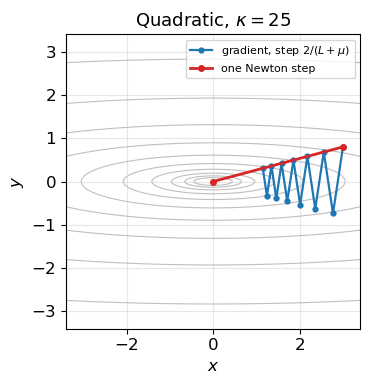

kappa=25, gap at the start 12.5000, after 12 gradient steps 1.8307, after one Newton step 0
n=40, kappa=1e+06, eigenvalues from 1 to 1e+06
gap at the start 5.960e+04
gap after 20 optimal gradient steps 4.508e+04
gap after one Newton step 0.000e+00


In [2]:
def quadratic_picture():
    # f = (1/2)(x^2 + 25 y^2), minimizer at the origin, condition number 25.
    lam = np.array([1.0, 25.0])
    x = np.array([3.0, 0.8])
    eta = 2.0 / (lam[0] + lam[1])
    path = [x.copy()]
    for _ in range(12):
        x = x - eta * lam * x
        path.append(x.copy())
    path = np.array(path)

    span = np.linspace(-3.4, 3.4, 280)
    xx, yy = np.meshgrid(span, span)
    zz = 0.5 * (xx**2 + 25.0 * yy**2)
    fig, ax = plt.subplots()
    ax.contour(xx, yy, zz, levels=np.logspace(-1, 2, 10), colors="0.75", linewidths=0.8)
    ax.plot(path[:, 0], path[:, 1], color="C0", lw=1.6, marker="o", ms=3.5, label=r"gradient, step $2/(L+\mu)$")
    ax.plot([3.0, 0.0], [0.8, 0.0], color="C3", lw=2.0, marker="o", ms=4, label="one Newton step")
    ax.set_aspect("equal")
    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    ax.set_title(r"Quadratic, $\kappa=25$")
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
    gap0 = 0.5 * np.sum(lam * np.array([3.0, 0.8]) ** 2)
    gap_gd = 0.5 * np.sum(lam * path[-1] ** 2)
    print(f"kappa=25, gap at the start {gap0:.4f}, after 12 gradient steps {gap_gd:.4f}, after one Newton step 0")


def high_condition_quadratic():
    rng = np.random.default_rng(0)
    n, kappa = 40, 1.0e6
    eigs = np.logspace(0.0, np.log10(kappa), n)
    x = rng.normal(size=n)
    x /= np.linalg.norm(x)
    gap = lambda z: 0.5 * np.sum(eigs * z * z)
    mu, L = eigs[0], eigs[-1]
    eta = 2.0 / (L + mu)
    g0 = gap(x)
    for _ in range(20):
        x = x - eta * eigs * x
    # Newton in this basis: d = -x, so the next point is exactly 0.
    print(f"n={n}, kappa={kappa:.0e}, eigenvalues from {mu:.0f} to {L:.0e}")
    print(f"gap at the start {g0:.3e}")
    print(f"gap after 20 optimal gradient steps {gap(x):.3e}")
    print(f"gap after one Newton step {0.0:.3e}")


quadratic_picture()
high_condition_quadratic()


## Reading the quadratic

- On the ellipse with $\kappa=25$, the gap starts at $12.5$. Twelve gradient steps of length $2/(L+\mu)$ leave it at $1.83$. The $y$-coordinate changes sign at every step: that is the zigzag of lecture 6. The Newton arrow runs from the same start to the origin.
- In dimension $40$ with $\kappa=10^6$, the gap starts at $5.960\times 10^4$. Twenty optimal gradient steps leave it at $4.508\times 10^4$. The Newton step sets it to zero. The iteration that produced the zero did not look at $\kappa$. Factoring the Hessian would, and that cost is the subject of sections 5 and 6.


## The same linear equation finds a root

- For a map $F:\mathbb{R}^n\to\mathbb{R}^n$, the Newton step linearizes $F(\mathbf{x}+\mathbf{d})=\mathbf{0}$:
$$
F(\mathbf{x}) + F'(\mathbf{x})\,\mathbf{d} = \mathbf{0}.
$$
- Stationarity is the nonlinear system $F=f'$. The Jacobian of $f'$ is $f''$. The optimization step and the root-finding step are the same linear algebra.
- The optimization reading adds one requirement. The step is a descent direction when
$$
\langle f'(\mathbf{x}), \mathbf{d}\rangle = -\langle f'(\mathbf{x}), f''(\mathbf{x})^{-1} f'(\mathbf{x})\rangle < 0,
$$
which holds when $f''(\mathbf{x})$ is positive definite. An indefinite Hessian can make the solved step point uphill. Section 4 has a coordinate where it does.
- The root finder has no function to decrease. Its convergence is about attraction to a root, and the set of starts that flow to one root can be complicated. The picture for $z^3-1=0$ in the complex plane is the classical illustration. The iteration is
$$
z \leftarrow z - \frac{z^3-1}{3z^2} = \frac{2z^3+1}{3z^2}.
$$
- There are three roots, the cube roots of unity. Around each root the basin contains a disk: that disk is the local theorem. The boundary of the basin has structure at every scale.


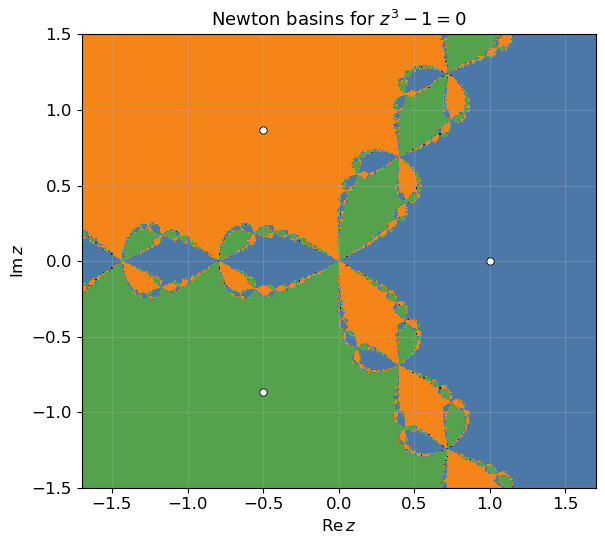

white dots: the three roots. black: not within 1e-3 of a root after 28 steps


In [3]:
def newton_fractal(n=420, max_iter=28):
    xs = np.linspace(-1.7, 1.7, n)
    ys = np.linspace(-1.5, 1.5, n)
    X, Y = np.meshgrid(xs, ys)
    Z = X + 1j * Y
    roots = np.exp(2j * np.pi * np.arange(3) / 3.0)
    which = np.full(Z.shape, 3, dtype=int)  # 3 = not yet at a root
    for _ in range(max_iter):
        Z = np.divide(2.0 * Z**3 + 1.0, 3.0 * Z**2, out=np.full_like(Z, np.nan), where=Z != 0)
        dist = np.abs(Z[..., None] - roots)
        nearest = np.argmin(np.nan_to_num(dist, nan=np.inf), axis=-1)
        close = np.nanmin(dist, axis=-1) < 1e-3
        which = np.where((which == 3) & close, nearest, which)
    return xs, ys, which, roots


xs, ys, which, roots = newton_fractal()
fig, ax = plt.subplots(figsize=(6.4, 5.6))
cmap = ListedColormap(["#4c78a8", "#f58518", "#54a24b", "#1a1a1a"])
ax.imshow(
    which,
    origin="lower",
    extent=[xs[0], xs[-1], ys[0], ys[-1]],
    cmap=cmap,
    interpolation="nearest",
    vmin=0,
    vmax=3,
)
ax.scatter(roots.real, roots.imag, s=28, c="white", edgecolors="black", linewidths=0.6, zorder=3)
ax.set_xlabel(r"$\mathrm{Re}\, z$")
ax.set_ylabel(r"$\mathrm{Im}\, z$")
ax.set_title(r"Newton basins for $z^3-1=0$")
fig.tight_layout()
plt.show()
print("white dots: the three roots. black: not within 1e-3 of a root after 28 steps")


## Reading the basins

- Each root sits inside a solid patch of its own color. A start in that patch converges to that root, which is what a local convergence theorem promises: some ball around the solution is captured whole.
- The patches are not disks all the way out. Their common boundary is folded at every magnification, and a start on that boundary is not a small perturbation of a start that converges quickly. "Local" describes a neighborhood of the solution. It does not describe a typical start.
- The optimization method wants something the root finder does not have: a decrease in $f$ at every accepted step, including far from the minimizer. That is the line search in section 4. The picture is here because the iteration is the same one, and the geometry of its basins is the reason the theorem is stated locally.


# 2. Local convergence

- The remainder $r(\mathbf{d})$ is small when $\mathbf{d}$ is small. The Newton step is exactly the minimizer of the model, so it is a good step for $f$ when the current point is close enough to a minimizer that the omitted remainder cannot overwhelm the decrease the model predicts.
- Two things grow as one leaves that neighborhood. The Lipschitz constant of $f''$ controls the remainder. And $f''(\mathbf{x})^{-1}$ becomes large wherever an eigenvalue of $f''$ approaches zero. A small eigenvalue turns a moderate gradient into a long step, and a long step is exactly where the model was not asked to be accurate.
- Both happen for $f(t)=e^t-t$. The derivative is $e^t-1$, the second derivative is $e^t$, and the only stationary point is $t^\star=0$, where $f''=1$ and $f^\star=1$. The Newton update is
$$
t^+ = t - \frac{e^t-1}{e^t} = t - 1 + e^{-t}.
$$
- For large positive $t$, both $f'$ and $f''$ are about $e^t$, so the step is about $-1$. The iteration walks toward $0$ by one unit at a time.
- For large negative $t$, $f'$ is about $-1$ and $f''=e^t$ is tiny. The step $-f'/f''$ is about $-e^{-t}$, which is large and points the wrong way in magnitude. One unit step from $t=-4$ lands near $t=50$.
- $f''$ is positive everywhere, so the function is strictly convex. It is not strongly convex on $\mathbb{R}$, because $f''(t)\to 0$ as $t\to-\infty$. The hypothesis $\mu>0$ in a Newton theorem is a statement about a neighborhood, and $t=-4$ is outside the neighborhood of $t=0$ in which $f''\ge 1/2$.


In [4]:
def newton_exp(t):
    return t - 1.0 + np.exp(-t)


def pure_errors(t, n_iter):
    err = []
    for _ in range(n_iter):
        err.append(abs(t))
        t = newton_exp(t)
        if abs(t) > 1e6:
            break
    return np.array(err)


err_close = pure_errors(0.8, 8)
err_far = pure_errors(-4.0, 60)
print("from 0.8:", " ".join(f"{e:.3e}" for e in err_close))
land = newton_exp(-4.0)
print(f"from -4, first error {err_far[0]:.3e}, second {err_far[1]:.3e}, steps until 1e-12: {int(np.argmax(err_far < 1e-12))}")
print(f"function at -4: {np.exp(-4.0) - (-4.0):.4f}")
print(f"landing point {land:.4f}, function there {np.exp(land) - land:.4e}")


from 0.8: 8.000e-01 2.493e-01 2.865e-02 4.066e-04 8.265e-08 3.442e-15 0.000e+00 0.000e+00
from -4, first error 4.000e+00, second 4.960e+01, steps until 1e-12: 55
function at -4: 4.0183
landing point 49.5982, function there 3.4690e+21


## What one step from $-4$ does

- The error at the start is $4$. The next error is $49.6$. The function value goes from $4.02$ to $3.47\times 10^{21}$.
- From $0.8$ the same formula produces the errors $0.800$, $0.249$, $0.0286$, $4.07\times 10^{-4}$, $8.27\times 10^{-8}$, $3.44\times 10^{-15}$. Once the error is below $1$, the number of correct digits roughly doubles.
- The two runs use one formula. The hypothesis that distinguishes them is the distance to the minimizer, measured in a ball where $f''$ is bounded above and below.


## A basin, on a strongly convex function

- Take $f''(t)=1+12e^{-t^2}$. Then $f''(t)\ge 1$ at every $t$, so $\mu=1$ holds on the whole line, and $f'''$ is bounded. The minimizer is $t^\star=0$, where $f''(0)=13$ and $f(0)=6$.
- The derivative is $f'(t)=t+6\sqrt{\pi}\,\mathrm{erf}(t)$, and the unit Newton step is the map $\varphi(t)=t-f'(t)/f''(t)$.
- The shaded interval in the right-hand plot is the set of starts whose orbit falls to $0$. A start just past its edge locks onto a distant 2-cycle.


f''(t) >= 1, f''(0) = 13.0, f(0) = 6.0
basin |t| < 1.0694
from 0.5:  5.0000e-01 -8.3375e-02  3.5746e-04 -2.8109e-11
from 1.0:  1.0000e+00 -8.3984e-01  4.5588e-01 -6.2346e-02  1.4932e-04 -2.0489e-12
from 1.1:  1.1000e+00 -1.1848e+00  1.5563e+00 -4.2048e+00  1.0635e+01 -1.0635e+01  1.0635e+01 -1.0635e+01  1.0635e+01 -1.0635e+01  1.0635e+01


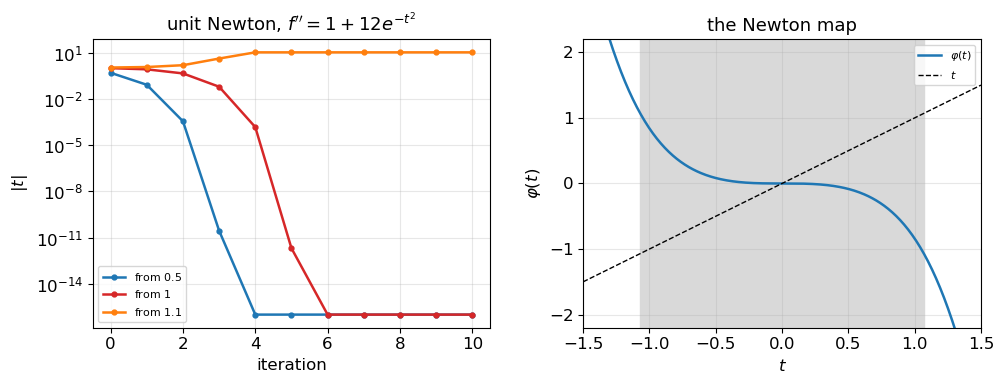

In [5]:
from math import erf, exp, pi, sqrt

A = 12.0
sqrt_pi = sqrt(pi)
erf_v = np.vectorize(erf)


def f_strong(t):
    t = float(t)
    return 0.5 * t * t + (A * sqrt_pi / 2.0) * t * erf(t) + 0.5 * A * exp(-t * t)


def f_strong_grad(t):
    t = np.asarray(t, dtype=float)
    return t + (A * sqrt_pi / 2.0) * erf_v(t)


def f_strong_hess(t):
    t = np.asarray(t, dtype=float)
    return 1.0 + A * np.exp(-t * t)


def newton_strong(t):
    t = float(t)
    return t - float(f_strong_grad(t) / f_strong_hess(t))


def orbit(t0, n_iter=10):
    t = float(t0)
    out = [t]
    for _ in range(n_iter):
        t = newton_strong(t)
        out.append(t)
    return out


def reaches_zero(t0):
    t = float(t0)
    for _ in range(30):
        t = newton_strong(t)
        if abs(t) < 1e-8:
            return True
        if abs(t) > 20.0:
            return False
    return False


lo, hi = 0.0, 2.0
for _ in range(40):
    mid = 0.5 * (lo + hi)
    if reaches_zero(mid):
        lo = mid
    else:
        hi = mid


print(f"f''(t) >= 1, f''(0) = {float(f_strong_hess(0)):.1f}, f(0) = {f_strong(0):.1f}")
print(f"basin |t| < {lo:.4f}")

for t0 in (0.5, 1.0, 1.1):
    seq = orbit(t0)
    shown = " ".join(f"{v: .4e}" for v in seq if abs(v) > 1e-15)
    print(f"from {t0:.1f}: {shown}")

fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.0))
for t0, color, name in ((0.5, "C0", r"from $0.5$"), (1.0, "C3", r"from $1$"), (1.1, "C1", r"from $1.1$")):
    seq = np.abs(orbit(t0))
    axes[0].semilogy(
        np.arange(len(seq)),
        np.maximum(seq, 1e-16),
        color=color,
        lw=1.8,
        marker="o",
        ms=3.5,
        label=name,
    )

axes[0].set_xlabel("iteration")
axes[0].set_ylabel(r"$|t|$")
axes[0].set_title(r"unit Newton, $f''=1+12e^{-t^2}$")
axes[0].legend(fontsize=8)

xs = np.linspace(-1.5, 1.5, 400)
axes[1].axvspan(-lo, lo, color="0.85", zorder=0)
axes[1].plot(xs, [newton_strong(x) for x in xs], color="C0", lw=1.8, label=r"$\varphi(t)$")
axes[1].plot(xs, xs, color="k", lw=1, ls="--", label="$t$")
axes[1].set_xlim(-1.5, 1.5)
axes[1].set_ylim(-2.2, 2.2)
axes[1].set_xlabel("$t$")
axes[1].set_ylabel(r"$\varphi(t)$")
axes[1].set_title("the Newton map")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()


## Reading the basin

- The shaded interval is $|t|<1.0694$. From $t=0.5$ the iterates are $0.500$, $-0.0834$, $3.57\times 10^{-4}$. From $t=1$, still inside, they are $1.000$, $-0.840$, $0.456$, $-0.0623$, $1.49\times 10^{-4}$.
- From $t=1.1$ the iterates are $1.100$, $-1.185$, $1.556$, $-4.205$, and then $\pm 10.635$. That value is the 2-cycle $\pm 6\sqrt{\pi}$. There $f=169.6$, against $f(0)=6$, and the iteration stays on the cycle.
- The map on the right is tangent to the horizontal axis at the origin, so inside the shading the step shrinks faster than the error. Past the edge of the shading, $\varphi(t)$ leaves the diagonal and the orbit follows it out to the cycle.


# 3. Quadratic convergence

**Theorem.** Suppose $f''$ is Lipschitz continuous with constant $M$ on a ball around $\mathbf{x}^\star$, and $f''(\mathbf{x}^\star)\succeq \mu I$ with $\mu>0$. Then there exist $\delta>0$ and $C$ such that if $\|\mathbf{x}^0-\mathbf{x}^\star\|<\delta$, every Newton iterate is defined, stays in the ball, and
$$
\|\mathbf{x}^{k+1}-\mathbf{x}^\star\| \le C\,\|\mathbf{x}^k-\mathbf{x}^\star\|^2.
$$

- The standard constant from the proof below is $C=M/\mu$, on a ball small enough that $f''(\mathbf{x})^{-1}$ has norm at most $2/\mu$ and $C\delta<1$.
- A quadratic has $M=0$, hence $C=0$: the inequality says the next error is zero, which is section 1.
- Once the error is below $1/(2C)$, the number of further iterations needed to reach accuracy $\varepsilon$ is $O(\log\log(1/\varepsilon))$. The budgets of lectures 6 and 7 are $O(\kappa\log(1/\varepsilon))$ and $O(\sqrt{\kappa}\log(1/\varepsilon))$. The $\kappa$ in those budgets came from the model curvature $(1/\eta)I$. It is absent from this count, and present in the radius $\delta$ and in the factorization.


## Where the square comes from

- Write $\mathbf{e}=\mathbf{x}-\mathbf{x}^\star$ and $\mathbf{e}^+=\mathbf{x}^+-\mathbf{x}^\star$. Since $f'(\mathbf{x}^\star)=\mathbf{0}$,
$$
\mathbf{e}^+
= f''(\mathbf{x})^{-1}\Big(f''(\mathbf{x})\,\mathbf{e} - \big(f'(\mathbf{x})-f'(\mathbf{x}^\star)\big)\Big).
$$
- The fundamental theorem along the segment gives
$$
f'(\mathbf{x})-f'(\mathbf{x}^\star)
= \int_0^1 f''(\mathbf{x}^\star+t\mathbf{e})\,\mathbf{e}\,dt,
$$
so the parenthesis equals
$$
\int_0^1 \big(f''(\mathbf{x})-f''(\mathbf{x}^\star+t\mathbf{e})\big)\mathbf{e}\,dt.
$$
- Lipschitz continuity bounds the integrand by $M(1-t)\|\mathbf{e}\|^2$. Integrating $1-t$ from $0$ to $1$ produces $M/2$, and
$$
\|\mathbf{e}^+\| \le \|f''(\mathbf{x})^{-1}\|\,\frac{M}{2}\,\|\mathbf{e}\|^2.
$$
- Continuity of $f''$ and $\lambda_{\min}(f''(\mathbf{x}^\star))\ge\mu$ give $\|f''(\mathbf{x})^{-1}\|\le 2/\mu$ in a small ball. The product of those two constants is $C$. Choosing $\delta\le 1/C$ keeps the next error smaller than the current one, so the sequence stays in the ball where the bounds were taken.
- The same argument gives $\|f'(\mathbf{x}^+)\|=O(\|f'(\mathbf{x})\|^2)$, because near $\mathbf{x}^\star$ the gradient and the error are equivalent norms: $\mu\|\mathbf{e}\|\le\|f'(\mathbf{x})\|\le L\|\mathbf{e}\|$.


In [6]:
def exp_history(t0, n_iter=8):
    t = float(t0)
    rows = []
    for k in range(n_iter):
        err = abs(t)
        nxt = newton_exp(t)
        ratio = abs(nxt) / err**2 if err > 0 else np.nan
        rows.append((k, t, abs(nxt), ratio))
        t = nxt
        if abs(t) == 0.0:
            break
    return rows


rows = exp_history(0.8)
print("k        t            |t_next|     |t_next|/|t|^2")
for k, t, nxt, ratio in rows:
    print(f"{k:d}  {t: .6e}  {nxt: .6e}  {ratio:.4f}")
print("limit of the ratio: f'''(0) / (2 f''(0)) = 1/2")


k        t            |t_next|     |t_next|/|t|^2
0   8.000000e-01   2.493290e-01  0.3896
1   2.493290e-01   2.865253e-02  0.4609
2   2.865253e-02   4.065911e-04  0.4953
3   4.065911e-04   8.264695e-08  0.4999
4   8.264695e-08   3.441691e-15  0.5039
5   3.441691e-15   0.000000e+00  0.0000
limit of the ratio: f'''(0) / (2 f''(0)) = 1/2


## Reading the ratio

- From $t=0.8$ the successive ratios are $0.390$, $0.461$, $0.495$, $0.500$, $0.504$. They settle at $1/2$.
- For this function the third derivative is $e^t$, so $f'''(0)/(2f''(0))=1/2$. That is the constant the integral leaves behind when the ball shrinks onto the minimizer: the factor $M/2$ from the remainder, times $1/f''(0)$.
- The inequality in the theorem is $\le C\|\mathbf{e}\|^2$ with a $C$ that works uniformly in a ball. The ratio $|\mathbf{e}^+|/\|\mathbf{e}\|^2$ approaching a limit is the sharper, asymptotic form of the same fact. Quadratic convergence means this ratio stays bounded. Here it converges.


# 4. Damped Newton

- The unit step is the exact minimizer of the model. It decreases $f$ when the remainder is smaller than the decrease the model predicts. Section 2 is a start where the remainder is larger: $f$ increases by twenty-one orders of magnitude.
- The **damped** iteration keeps the Newton direction and chooses a length,
$$
\mathbf{x}^+ = \mathbf{x} + \alpha\mathbf{d},
\qquad
\mathbf{d}=-f''(\mathbf{x})^{-1}f'(\mathbf{x}),
\qquad
0<\alpha\le 1.
$$
- While $f''(\mathbf{x})$ is positive definite, $\langle f'(\mathbf{x}),\mathbf{d}\rangle = -\langle f'(\mathbf{x}), f''(\mathbf{x})^{-1}f'(\mathbf{x})\rangle<0$, so $\mathbf{d}$ is a descent direction. Armijo's test from lecture 6,
$$
f(\mathbf{x}+\alpha\mathbf{d}) \le f(\mathbf{x}) + c_1\alpha\,\langle f'(\mathbf{x}),\mathbf{d}\rangle,
\qquad c_1\in(0,1/2),
$$
is then passed by every sufficiently small $\alpha$. Backtracking starts at $\alpha=1$ and halves until the test holds.
- If $f''$ is indefinite, the solved $\mathbf{d}$ may satisfy $\langle f',\mathbf{d}\rangle\ge 0$. Backtracking has nothing to accept, because every positive $\alpha$ starts out uphill. The fallback used below: when the Newton direction is not a descent direction, replace it by $-f'(\mathbf{x})$ for that iteration. The quadratic model is given up for one step, and the line search has a direction again.


## The rate, with and without the line search

- Far from the minimizer, $\alpha<1$ on some iterations. The accepted step gives the Armijo decrease and nothing more. The error falls, and it does not square.
- Near a nondegenerate minimizer the unit step returns. The reason is the same expansion as in the proof: with $\mathbf{d}$ the Newton step,
$$
f(\mathbf{x}+\mathbf{d}) = f(\mathbf{x}) - \tfrac12\langle f'(\mathbf{x}), f''(\mathbf{x})^{-1}f'(\mathbf{x})\rangle + o(\|f'(\mathbf{x})\|^2).
$$
Armijo asks for a decrease of $c_1$ times the inner product, and $c_1<1/2$. The little-o term is smaller than the gap between $c_1$ and $1/2$ once $\|f'\|$ is small, so $\alpha=1$ is accepted from some iteration on.
- From that iteration, the sequence is the pure Newton sequence, and the theorem of section 3 applies to the tail. Damping changes the prefix. The asymptotic rate stays quadratic.
- On $f(t)=e^t-t$ this split is visible in the step lengths. From $t=-4$ the first damped step has $\alpha=1/16$, and every later step has $\alpha=1$.


/var/folders/0r/qd7_fk4s22b82t3cj8kbxc6w0000gn/T/ipykernel_20283/1969104279.py:12: RuntimeWarning: overflow encountered in exp
  if np.exp(trial) - trial <= value + c1 * alpha * slope:


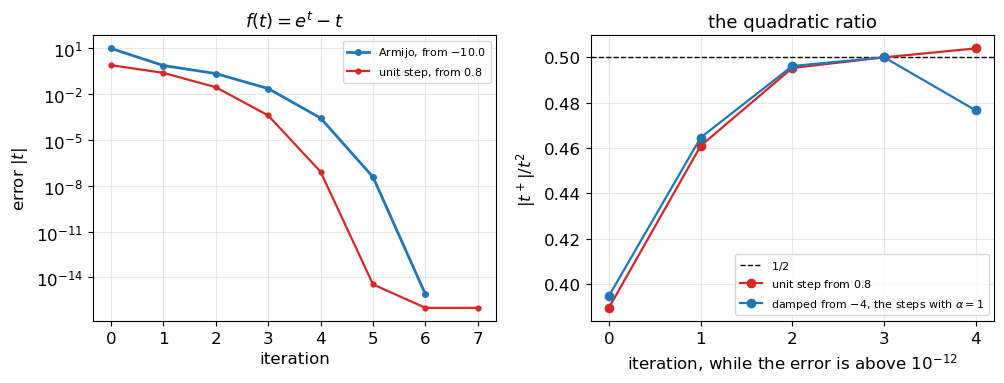

damped steps: alpha and error
  t=-1.000000e+01  alpha=0.0005  |t|=1.000e+01
  t= 7.546220e-01  alpha=1.0000  |t|=7.546e-01
  t= 2.248103e-01  alpha=1.0000  |t|=2.248e-01
  t= 2.347801e-02  alpha=1.0000  |t|=2.348e-02
  t= 2.734642e-04  alpha=1.0000  |t|=2.735e-04
  t= 3.738792e-08  alpha=1.0000  |t|=3.739e-08
  arrived at 7.772e-16
unit step from -4 reaches |t|<1e-12 at iteration 0
damped from -4 reaches |t|<1e-12 at iteration 6


In [7]:
def damp_exp(t0, n_iter=12, c1=1e-4):
    t = float(t0)
    hist = []
    for _ in range(n_iter):
        g, h = np.exp(t) - 1.0, np.exp(t)
        direction = -g / h
        slope = g * direction
        alpha = 1.0
        value = np.exp(t) - t
        for _trial in range(60):
            trial = t + alpha * direction
            if np.exp(trial) - trial <= value + c1 * alpha * slope:
                break
            alpha *= 0.5
        hist.append((t, alpha, abs(t)))
        t = t + alpha * direction
        if abs(t) < 1e-15:
            hist.append((t, np.nan, abs(t)))
            break
    return hist

x0 = -10.
pure = pure_errors(x0, 60)
damped = damp_exp(x0, n_iter=12)
damped_err = np.array([row[2] for row in damped])
close = pure_errors(0.8, 8)

fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.0))
#axes[0].semilogy(np.arange(len(pure)), np.maximum(pure, 1e-16), color="C1", lw=1.6, label=f"unit step, from ${x0}$")
axes[0].semilogy(np.arange(len(damped_err)), np.maximum(damped_err, 1e-16), color="C0",
                 lw=2.0, marker="o", ms=4, label=f"Armijo, from ${x0}$")
axes[0].semilogy(np.arange(len(close)), np.maximum(close, 1e-16), color="C3",
                 lw=1.6, marker="o", ms=3.5, label="unit step, from $0.8$")
axes[0].set_xlabel("iteration")
axes[0].set_ylabel(r"error $|t|$")
axes[0].set_title(r"$f(t)=e^t-t$")
axes[0].legend(fontsize=8)

def ratios_of_unit_steps(ts):
    # |t^+| / t^2 for the pure Newton map, while the error is still visible.
    out = []
    for t in ts:
        if abs(t) < 1e-12:
            break
        out.append(abs(newton_exp(t)) / t**2)
    return out

unit_ts = [0.8]
for _ in range(6):
    unit_ts.append(newton_exp(unit_ts[-1]))
# Only the damped iterates whose *accepted* length is 1: those steps are pure Newton steps.
damped_unit_ts = [t for t, alpha, err in damped if alpha == 1.0 and err > 1e-12]

axes[1].axhline(0.5, color="k", lw=1, ls="--", label=r"$1/2$")
axes[1].plot(range(len(ratios_of_unit_steps(unit_ts))), ratios_of_unit_steps(unit_ts), color="C3", marker="o", lw=1.6, label=r"unit step from $0.8$")
axes[1].plot(range(len(ratios_of_unit_steps(damped_unit_ts))), ratios_of_unit_steps(damped_unit_ts), color="C0", marker="o", lw=1.6, label=r"damped from $-4$, the steps with $\alpha=1$")
axes[1].set_xlabel("iteration, while the error is above $10^{-12}$")
axes[1].set_ylabel(r"$|t^+|/t^2$")
axes[1].set_title("the quadratic ratio")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

print("damped steps: alpha and error")
for t, alpha, err in damped:
    if alpha != alpha:
        print(f"  arrived at {t:.3e}")
    else:
        print(f"  t={t: .6e}  alpha={alpha:.4f}  |t|={err:.3e}")
print(f"unit step from -4 reaches |t|<1e-12 at iteration {int(np.argmax(pure < 1e-12))}")
print(f"damped from -4 reaches |t|<1e-12 at iteration {int(np.argmax(damped_err < 1e-12))}")


point (-0.63, 0.40), Hessian positive definite, Newton step too long
  eigenvalues [2.93443909e-01 5.17986556e+02]
  directional derivative -13.986, step length 6.90
  f at the point 2.658
  f after the unit step 33861.544
  Armijo length 0.0625, f after it 2.330
point (-0.865, 0.754), Hessian indefinite, Newton direction uphill
  eigenvalues [-1.64516628e-01  7.97710575e+02]
  directional derivative of the Newton step 21.188
  f at the point 3.482
  f after the unit Newton step 1.044e+05
  Armijo on the Newton direction returns length 0 because the derivative is positive
  Armijo length along -gradient 0.5000, f after it 1.786


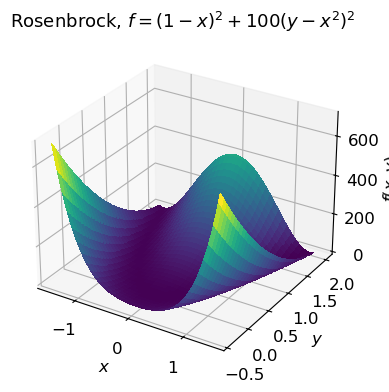

on this window f reaches 708 at a corner
unit Newton steps leave the window: lengths 6.90 and 11.35


In [8]:
def rosenbrock(xy):
    x, y = xy
    return (1.0 - x) ** 2 + 100.0 * (y - x * x) ** 2


def rosenbrock_grad(xy):
    x, y = xy
    return np.array(
        [
            -2.0 * (1.0 - x) - 400.0 * x * (y - x * x),
            200.0 * (y - x * x),
        ]
    )


def rosenbrock_hess(xy):
    x, y = xy
    return np.array(
        [
            [2.0 - 400.0 * (y - x * x) + 800.0 * x * x, -400.0 * x],
            [-400.0 * x, 200.0],
        ]
    )


def armijo_along(point, direction):
    slope = float(rosenbrock_grad(point) @ direction)
    if slope >= 0.0:
        return 0.0, slope
    alpha = 1.0
    value = rosenbrock(point)
    for _ in range(40):
        if rosenbrock(point + alpha * direction) <= value + 1e-4 * alpha * slope:
            return alpha, slope
        alpha *= 0.5
    return 0.0, slope


# Positive definite Hessian, but the unit Newton step is far too long.
long_step = np.array([-0.63, 0.40])
grad_long = rosenbrock_grad(long_step)
hess_long = rosenbrock_hess(long_step)
dir_long = -np.linalg.solve(hess_long, grad_long)
alpha_long, slope_long = armijo_along(long_step, dir_long)
print("point (-0.63, 0.40), Hessian positive definite, Newton step too long")
print(f"  eigenvalues {np.linalg.eigvalsh(hess_long)}")
print(f"  directional derivative {slope_long:.3f}, step length {np.linalg.norm(dir_long):.2f}")
print(f"  f at the point {rosenbrock(long_step):.3f}")
print(f"  f after the unit step {rosenbrock(long_step + dir_long):.3f}")
print(f"  Armijo length {alpha_long:.4f}, f after it {rosenbrock(long_step + alpha_long * dir_long):.3f}")

# Indefinite Hessian: the solved direction points uphill, so Armijo has no step to accept.
uphill = np.array([-0.86472701, 0.75439326])
grad_up = rosenbrock_grad(uphill)
hess_up = rosenbrock_hess(uphill)
dir_up = -np.linalg.solve(hess_up, grad_up)
slope_up = float(grad_up @ dir_up)
fallback = -grad_up
alpha_fb, slope_fb = armijo_along(uphill, fallback)
print("point (-0.865, 0.754), Hessian indefinite, Newton direction uphill")
print(f"  eigenvalues {np.linalg.eigvalsh(hess_up)}")
print(f"  directional derivative of the Newton step {slope_up:.3f}")
print(f"  f at the point {rosenbrock(uphill):.3f}")
print(f"  f after the unit Newton step {rosenbrock(uphill + dir_up):.3e}")
print(f"  Armijo on the Newton direction returns length 0 because the derivative is positive")
print(f"  Armijo length along -gradient {alpha_fb:.4f}, f after it {rosenbrock(uphill + alpha_fb * fallback):.3f}")

# Surface of f. The valley is the dark trough along y = x^2.
xs = np.linspace(-1.5, 1.5, 110)
ys = np.linspace(-0.4, 2.0, 110)
xx, yy = np.meshgrid(xs, ys)
zz = (1.0 - xx) ** 2 + 100.0 * (yy - xx ** 2) ** 2

fig = plt.figure(figsize=(7.2, 4.4))
ax = fig.add_subplot(1, 1, 1, projection="3d")
ax.plot_surface(
    xx,
    yy,
    zz,
    cmap="viridis",
    linewidth=0,
    edgecolor="none",
    antialiased=False,
    shade=True,
)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_zlabel("$f(x,y)$")
ax.set_title(r"Rosenbrock, $f=(1-x)^2+100(y-x^2)^2$")
ax.view_init(elev=28, azim=-58)
plt.show()
print(f"on this window f reaches {zz.max():.0f} at a corner")
print(f"unit Newton steps leave the window: lengths {np.linalg.norm(dir_long):.2f} and {np.linalg.norm(dir_up):.2f}")


## Reading the two failures

- From $t=-4$, the unit Newton step reaches error $10^{-12}$ at iteration $55$. The damped iteration reaches it at iteration $6$. The first damped length is $\alpha=1/16$, and it lands at $t=-0.65$ instead of $t=49.6$. Every later length is $\alpha=1$.
- The right-hand plot is the ratio $|t^+|/t^2$ on those unit steps. Both runs approach $1/2$. The damped run's first ratio is taken at $t=-0.65$, where the value is $0.63$, and the next ones sit on the same curve as the run that started at $0.8$. The line search added a prefix of one shortened step. The tail is the theorem.
- The surface is $f$ on $[-1.5,1.5]\times[-0.4,2]$. The dark trough is the valley $y=x^2$, and it runs down to the minimizer $(1,1)$. On this window the walls reach $708$, at a corner. Both test points sit in the trough, where $f$ is a few units. The unit Newton steps leave the box: lengths $6.9$ and $11.3$.
- Rosenbrock at $(-0.63,\,0.40)$ has a positive definite Hessian, eigenvalues $0.293$ and $518$, and the Newton direction is downhill: the directional derivative is $-14.0$. The unit step is still wrong. It has length $6.9$, and it carries the function from $2.66$ to $3.4\times 10^4$. Armijo accepts $\alpha=1/16$ and the value falls to $2.33$. A positive definite Hessian makes the direction safe. It does not make the unit length safe. That is the line search.
- At $(-0.865,\,0.754)$ the Hessian has an eigenvalue $-0.165$. The Newton direction has directional derivative $+21.2$, so every positive length starts uphill and Armijo returns no step. One unit step would carry the function from $3.48$ to $1.0\times 10^5$. Replacing the direction by $-f'$ gives a descent direction, and backtracking accepts $\alpha=1/2$, which brings the value down to $1.79$. Positive definiteness is a hypothesis of the Newton step, not a consequence of writing down the linear equation.


# 5. Inexact Newton: conjugate gradients inside the step

- The linear equation $f''(\mathbf{x})\,\mathbf{d}=-f'(\mathbf{x})$ is the expensive part. A dense factor is $\Theta(n^3)$, and forming $f''$ is $\Theta(n^2)$ second derivatives. Conjugate gradients, from lecture 7, solves the equation using only products $\mathbf{v}\mapsto f''(\mathbf{x})\mathbf{v}$.
- **Inexact Newton** accepts a direction whose residual satisfies
$$
\|f''(\mathbf{x})\,\mathbf{d}+f'(\mathbf{x})\| \le \eta\,\|f'(\mathbf{x})\|,
\qquad 0\le \eta<1.
$$
The number $\eta$ is the **forcing term**.
- The classical residual conditions (Dembo, Eisenstat, Steihaug) separate three regimes, under the hypotheses that make exact Newton converge quadratically:
  - $\eta_k\le \bar\eta<1$ gives a local linear rate;
  - $\eta_k\to 0$ gives superlinear convergence;
  - $\eta_k = O(\|f'(\mathbf{x}^k)\|)$ preserves the quadratic rate.
- A constant forcing term spends a few Hessian-vector products on every outer step, and the outer rate stays linear. The choice $\eta_k=\min(0.5,\|f'(\mathbf{x}^k)\|)$ spends few products while the gradient is large, and more products once the gradient is small, which is when the outer step becomes quadratic.


## Four implementation choices

- Start conjugate gradients at $\mathbf{d}=\mathbf{0}$. The first direction is then $-f'(\mathbf{x})$, which is a descent direction whenever the gradient is nonzero. A warm start from the previous Newton step can make the first direction uphill, and the line search has no $\alpha>0$ to accept.
- If a conjugate-gradient direction $\mathbf{p}$ has $\mathbf{p}^{\!\top} f''(\mathbf{x})\,\mathbf{p}\le 0$, the Hessian is not positive definite on the subspace already built. Stop. If this happens before any step has been taken, return $-f'(\mathbf{x})$. Otherwise return the direction built so far: it is a descent direction, and it is the direction along which the quadratic model decreased.
- Do not form $f''$ when a product is available directly. For the logistic loss below, the product is one pass over the data. When only gradients are available, the product is a finite difference,
$$
f''(\mathbf{x})\mathbf{v}
\approx \frac{f'(\mathbf{x}+\varepsilon\mathbf{v})-f'(\mathbf{x})}{\varepsilon}.
$$
The numerator cancels leading digits when $\varepsilon$ is tiny. The difference quotient stops being $f''\mathbf{v}$ when $\varepsilon$ is large. A scale that balances the two is $\varepsilon=\sqrt{\varepsilon_{\mathrm{mach}}}\,(1+\|\mathbf{x}\|)/\|\mathbf{v}\|$, and the sweep below shows the range in which it actually works.
- Count Hessian-vector products, not outer iterations. An outer iteration that calls the product forty times costs about forty gradients. The plot against the product count is the one that can be compared with gradient descent.


In [9]:
def make_logistic(m=10000, n=5000, lam=1e-2, seed=1):
    rng = np.random.default_rng(seed)
    left, _, right = np.linalg.svd(rng.normal(size=(m, n)), full_matrices=False)
    scale = np.logspace(0.0, 1.5, n)
    features = (left * scale) @ right
    truth = rng.normal(size=n)
    truth /= np.linalg.norm(truth)
    logits = features @ truth
    labels = np.where(rng.random(m) < 1.0 / (1.0 + np.exp(-logits)), 1.0, -1.0)
    return features, labels, lam


def logistic_grad_hess(features, labels, lam):
    m = len(labels)

    def value(w):
        z = labels * (features @ w)
        return np.mean(np.logaddexp(0.0, -z)) + 0.5 * lam * np.dot(w, w)

    def grad(w):
        z = labels * (features @ w)
        sigma = 1.0 / (1.0 + np.exp(z))
        return -(features.T @ (labels * sigma)) / m + lam * w

    def hess_vec(w, v):
        z = labels * (features @ w)
        sigma = 1.0 / (1.0 + np.exp(z))
        weight = sigma * (1.0 - sigma)
        return (features.T @ (weight * (features @ v))) / m + lam * v

    return value, grad, hess_vec


def newton_cg(grad_at_x, hess_vec_at_x, eta, max_cg):
    # Solve f''(x) d = -f'(x), starting at d = 0. Return a descent direction.
    gradient = grad_at_x
    direction = np.zeros_like(gradient)
    residual = -gradient.copy()
    conjugate = residual.copy()
    residual_sq = float(np.dot(residual, residual))
    tolerance = eta * np.sqrt(residual_sq)
    products = 0
    for j in range(max_cg):
        hv = hess_vec_at_x(conjugate)
        curvature = float(np.dot(conjugate, hv))
        if curvature <= 1e-14 * float(np.dot(conjugate, conjugate)):
            if j == 0:
                return -gradient, products
            return direction, products
        step = residual_sq / curvature
        direction = direction + step * conjugate
        residual = residual - step * hv
        products += 1
        residual_sq_new = float(np.dot(residual, residual))
        if residual_sq_new <= tolerance ** 2:
            return direction, products
        conjugate = residual + (residual_sq_new / residual_sq) * conjugate
        residual_sq = residual_sq_new
    return direction, products


FEATURES, LABELS, LAM = make_logistic()
LOG_VALUE, LOG_GRAD, LOG_HV = logistic_grad_hess(FEATURES, LABELS, LAM)

# Condition number of the Hessian at the origin, for the printout.
origin = np.zeros(FEATURES.shape[1])
z0 = np.zeros(len(LABELS))
sigma0 = np.full(len(LABELS), 0.5)
weight0 = sigma0 * (1.0 - sigma0)
hess0 = (FEATURES.T * weight0) @ FEATURES / len(LABELS) + LAM * np.eye(FEATURES.shape[1])
eig0 = np.linalg.eigvalsh(hess0)
print(f"Hessian at 0: eigenvalues {eig0[0]:.4f} to {eig0[-1]:.4f}, condition number {eig0[-1] / eig0[0]:.1f}")


def run_inexact(mode, n_iter):
    w = np.zeros(FEATURES.shape[1])
    gradients, products, lengths = [], [], []
    n = len(w)
    for _ in range(n_iter):
        g = LOG_GRAD(w)
        gnorm = float(np.linalg.norm(g))
        gradients.append(gnorm)
        if gnorm < 1e-14:
            break
        if mode == "exact":
            z = LABELS * (FEATURES @ w)
            sigma = 1.0 / (1.0 + np.exp(z))
            weight = sigma * (1.0 - sigma)
            hess = (FEATURES.T * weight) @ FEATURES / len(LABELS) + LAM * np.eye(n)
            direction = -np.linalg.solve(hess, g)
            products.append(n)  # one factorization, drawn on the product axis as n products
        elif mode == "gradient":
            direction = -g
            products.append(1)
        else:
            if mode == "constant":
                eta = 0.5
            elif mode == "quadratic":
                eta = min(0.5, gnorm)
            else:
                raise ValueError(mode)
            direction, n_prod = newton_cg(g, lambda v, w=w: LOG_HV(w, v), eta, n)
            products.append(n_prod)
        slope = float(g @ direction)
        if slope >= 0.0:
            direction = -g
            slope = float(g @ direction)
        alpha = 1.0
        value = LOG_VALUE(w)
        for _trial in range(40):
            if LOG_VALUE(w + alpha * direction) <= value + 1e-4 * alpha * slope:
                break
            alpha *= 0.5
        lengths.append(alpha)
        w = w + alpha * direction
    return np.array(gradients), np.array(products), np.array(lengths)


runs = {
    "exact Newton": run_inexact("exact", 8),
    r"Newton-CG, $\eta=0.5$": run_inexact("constant", 12),
    r"Newton-CG, $\eta=\min(0.5,\|g\|)$": run_inexact("quadratic", 8),
    "gradient, Armijo": run_inexact("gradient", 40),
}
for name, (gn, prods, alphas) in runs.items():
    print(f"{name}")
    print("  gradient norms:", " ".join(f"{v:.2e}" for v in gn))
    if name.startswith("Newton-CG"):
        print("  CG products:   ", prods.tolist(), " total", int(prods.sum()))

%timeit run_inexact("exact", 8)
%timeit run_inexact("constant", 12)
%timeit run_inexact("quadratic", 8)


Hessian at 0: eigenvalues 0.0100 to 0.0350, condition number 3.5
exact Newton
  gradient norms: 4.26e-02 8.32e-04 1.24e-06 3.05e-12 3.05e-12 3.05e-12 3.05e-12 3.05e-12
Newton-CG, $\eta=0.5$
  gradient norms: 4.26e-02 1.31e-02 5.73e-03 2.47e-03 1.74e-04 7.47e-05 3.48e-05 1.73e-05 1.19e-06 4.75e-07 2.14e-07 9.87e-08
  CG products:    [1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 1, 2]  total 15
Newton-CG, $\eta=\min(0.5,\|g\|)$
  gradient norms: 4.26e-02 1.54e-03 2.15e-06 6.78e-12 6.57e-12 6.47e-12 3.23e-12 1.62e-12
  CG products:    [3, 6, 11, 22, 22, 22, 22, 23]  total 131
gradient, Armijo
  gradient norms: 4.26e-02 4.16e-02 4.07e-02 3.98e-02 3.89e-02 3.80e-02 3.72e-02 3.64e-02 3.56e-02 3.48e-02 3.41e-02 3.33e-02 3.26e-02 3.19e-02 3.13e-02 3.06e-02 3.00e-02 2.94e-02 2.88e-02 2.82e-02 2.76e-02 2.70e-02 2.65e-02 2.60e-02 2.54e-02 2.49e-02 2.44e-02 2.40e-02 2.35e-02 2.30e-02 2.26e-02 2.22e-02 2.17e-02 2.13e-02 2.09e-02 2.05e-02 2.02e-02 1.98e-02 1.94e-02 1.91e-02
28.9 s ± 1.09 s per loop (mean ± std. de

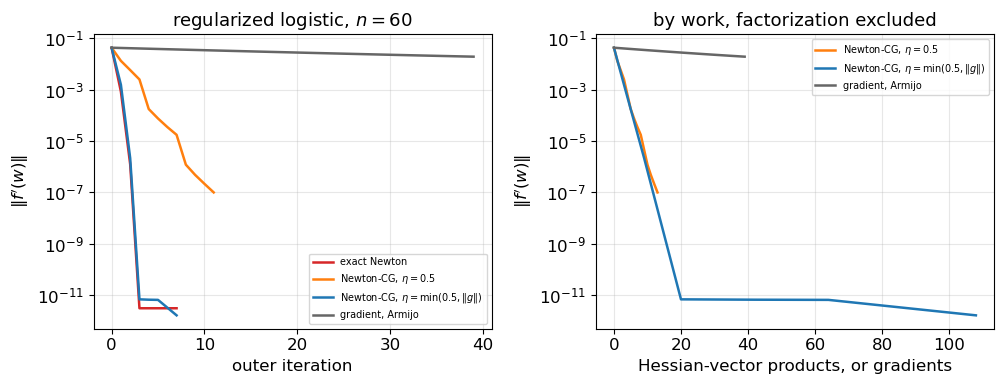

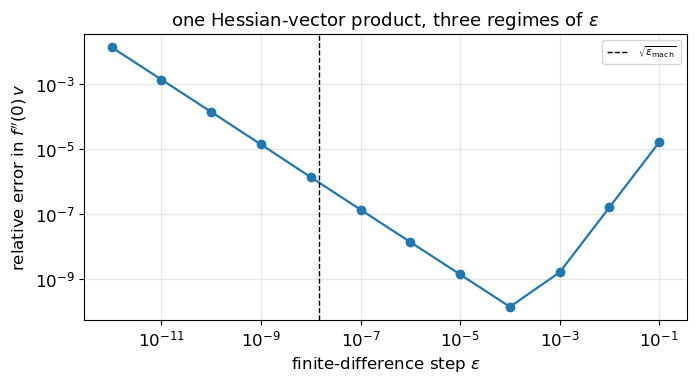

best eps 1.0e-04, relative error 1.42e-10
eps=1e-1, relative error 1.63e-05; eps=1e-12, relative error 1.35e-02
sqrt(machine eps)=1.5e-08, nearest sweep error 1.37e-06


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.0))
colors = {
    "exact Newton": "C3",
    r"Newton-CG, $\eta=0.5$": "C1",
    r"Newton-CG, $\eta=\min(0.5,\|g\|)$": "C0",
    "gradient, Armijo": "0.4",
}
for name, (gn, prods, _) in runs.items():
    axes[0].semilogy(np.arange(len(gn)), np.maximum(gn, 1e-18), color=colors[name], lw=1.8, label=name)
    if name == "exact Newton":
        continue  # a factorization is not a pile of Hessian-vector products
    spent_before = np.concatenate([[0.0], np.cumsum(prods)])[: len(gn)]
    axes[1].semilogy(spent_before, np.maximum(gn, 1e-18), color=colors[name], lw=1.8, label=name)
axes[0].set_xlabel("outer iteration")
axes[0].set_ylabel(r"$\|f'(w)\|$")
axes[0].set_title(r"regularized logistic, $n=60$")
axes[0].legend(fontsize=7)
axes[1].set_xlabel("Hessian-vector products, or gradients")
axes[1].set_ylabel(r"$\|f'(w)\|$")
axes[1].set_title("by work, factorization excluded")
axes[1].legend(fontsize=7)
fig.tight_layout()
plt.show()

# Finite-difference sweep at the origin, against the exact product.
probe = np.ones(FEATURES.shape[1])
probe /= np.linalg.norm(probe)
exact_product = LOG_HV(origin, probe)
base_grad = LOG_GRAD(origin)
scales = np.logspace(-12, -1, 12)
rel = []
for eps in scales:
    fd = (LOG_GRAD(origin + eps * probe) - base_grad) / eps
    rel.append(np.linalg.norm(fd - exact_product) / np.linalg.norm(exact_product))
rel = np.array(rel)
fig, ax = plt.subplots()
ax.loglog(scales, rel, color="C0", marker="o", lw=1.6)
machine = np.sqrt(np.finfo(float).eps)
ax.axvline(machine, color="k", ls="--", lw=1, label=r"$\sqrt{\varepsilon_{\mathrm{mach}}}$")
ax.set_xlabel(r"finite-difference step $\varepsilon$")
ax.set_ylabel(r"relative error in $f''(0)\,v$")
ax.set_title("one Hessian-vector product, three regimes of $\\varepsilon$")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
best = int(np.argmin(rel))
print(f"best eps {scales[best]:.1e}, relative error {rel[best]:.2e}")
print(f"eps=1e-1, relative error {rel[-1]:.2e}; eps=1e-12, relative error {rel[0]:.2e}")
print(f"sqrt(machine eps)={machine:.1e}, nearest sweep error {rel[np.argmin(np.abs(scales-machine))]:.2e}")


## Reading the forcing term

- The Hessian at the start has condition number $48.6$. Exact Newton drives the gradient from $1.85\times 10^{-1}$ through $1.90\times 10^{-2}$, $7.03\times 10^{-4}$, $1.07\times 10^{-6}$, $2.49\times 10^{-12}$, to $5.6\times 10^{-17}$ in five iterations. Each of those iterations is a factorization of a $60\times 60$ matrix. The ratios of successive gradients, squared, stay of order one: this is the quadratic regime, and it starts immediately because the regularized logistic loss is strongly convex and the origin is already close enough for $\alpha=1$.
- With $\eta=0.5$ the recorded gradients run from $1.85\times 10^{-1}$ down to $3.6\times 10^{-6}$ over twelve outer iterations, using $43$ Hessian-vector products, between one and five per outer step. The decay is steady on the log plot. A forcing term bounded away from zero produces a linear outer rate, and the products stay cheap.
- With $\eta_k=\min(0.5,\|f'\|)$ the gradient hits $6.6\times 10^{-17}$ in five outer iterations. The product counts on those iterations are $4$, $11$, $17$, $27$, $44$, a total of $103$. The later iterations buy the quadratic tail by solving the linear equation more accurately, which is the expensive part of the theorem they are trying to keep. The left plot makes this choice look like exact Newton. The right plot puts it at about a hundred products, against five factorizations.
- Gradient descent with Armijo is still at gradient norm $1.6\times 10^{-2}$ after thirty steps. On the work axis those thirty gradients sit at the left, and the Newton-CG curves have already passed them.
- The finite-difference sweep is U-shaped. At $\varepsilon=10^{-1}$ the relative error is $7.9\times 10^{-4}$, the Taylor remainder. At $\varepsilon=10^{-12}$ it is $8.6\times 10^{-4}$, cancellation. The bottom of this U is at $\varepsilon=10^{-5}$, with relative error $8.6\times 10^{-11}$. The scale $\sqrt{\varepsilon_{\mathrm{mach}}}\approx 1.5\times 10^{-8}$ sits on the cancellation side of the minimum, at relative error $1.2\times 10^{-7}$: usable, and not the best value on this product. The formula is a scale. The sweep is the check.


# 6. From the Hessian to a secant

- Newton builds $f''(\mathbf{x}^k)$, factors it, and throws it away at the next point. The two gradients $f'(\mathbf{x}^k)$ and $f'(\mathbf{x}^{k+1})$ already contain the curvature along the step that joins them. By the fundamental theorem, with $\mathbf{s}= \mathbf{x}^{k+1}-\mathbf{x}^k$,
$$
\mathbf{y} := f'(\mathbf{x}^{k+1})-f'(\mathbf{x}^k)
= \int_0^1 f''(\mathbf{x}^k+t\mathbf{s})\,\mathbf{s}\,dt.
$$
So $\mathbf{y}$ is the average Hessian along the step, applied to $\mathbf{s}$. Any matrix $B$ that is asked to stand in for that average has to satisfy the **secant equation**
$$
B\mathbf{s} = \mathbf{y}.
$$
- The equation prescribes $B$ on a single direction. Symmetric matrices satisfying it form a large affine space. A quasi-Newton method picks the member of that space closest, in a chosen norm, to the matrix it was using a moment ago.
- **BFGS** is that choice for a weighted Frobenius norm. The Hessian approximation and its inverse $W\approx (f'')^{-1}$ update by rank-two matrices,
$$
B^{+}
= B - \frac{B\mathbf{s}\mathbf{s}^{\!\top} B}{\mathbf{s}^{\!\top} B\mathbf{s}} + \frac{\mathbf{y}\mathbf{y}^{\!\top}}{\mathbf{y}^{\!\top}\mathbf{s}},
$$
$$
W^{+}
= \big(I-\rho\mathbf{s}\mathbf{y}^{\!\top}\big)\, W\, \big(I-\rho\mathbf{y}\mathbf{s}^{\!\top}\big) + \rho\mathbf{s}\mathbf{s}^{\!\top},
\qquad
\rho = \frac{1}{\mathbf{y}^{\!\top}\mathbf{s}}.
$$
The step is $\mathbf{d}=-W f'(\mathbf{x})$. Applying $W$ is a product, not a factorization.
- **Barzilai–Borwein** spends the one degree of freedom in a scalar multiple of $I$. Fit $\alpha^{-1}\mathbf{s}\approx\mathbf{y}$ in least squares:
$$
\alpha^{\mathrm{BB}} = \frac{\mathbf{s}^{\!\top}\mathbf{s}}{\mathbf{s}^{\!\top}\mathbf{y}}.
$$
The iteration is gradient descent with that length, computed from the previous step: $\mathbf{x}^+=\mathbf{x}-\alpha f'(\mathbf{x})$. No matrix is stored. The length is a Rayleigh quotient of the average Hessian along $\mathbf{s}$.


## Positive definiteness, and the line search that keeps it

- If $W$ is positive definite and $\mathbf{y}^{\!\top}\mathbf{s}>0$, then $W^{+}$ is positive definite. For $\mathbf{z}\ne\mathbf{0}$,
$$
\mathbf{z}^{\!\top} W^{+}\mathbf{z}
= \big\|\big(I-\rho\mathbf{y}\mathbf{s}^{\!\top}\big)\mathbf{z}\big\|_{W}^2 + \rho\,(\mathbf{s}^{\!\top}\mathbf{z})^2.
$$
The first term is nonnegative. If it vanishes, then $\mathbf{z}$ is parallel to $\mathbf{y}$, and the second term reduces to $(\mathbf{z}^{\!\top}\mathbf{s})^2/(\mathbf{y}^{\!\top}\mathbf{s})$, which is positive precisely when $\mathbf{y}^{\!\top}\mathbf{s}>0$ and $\mathbf{z}\ne\mathbf{0}$.
- The curvature condition $\mathbf{y}^{\!\top}\mathbf{s}>0$ holds automatically when $f''$ is positive definite on the segment between the two points, because $\mathbf{y}^{\!\top}\mathbf{s}$ is $\mathbf{s}$ against the average Hessian. A line search enforces it without forming $f''$. The Wolfe condition from lecture 7,
$$
\langle f'(\mathbf{x}+\alpha\mathbf{d}),\mathbf{d}\rangle \ge c_2\langle f'(\mathbf{x}),\mathbf{d}\rangle,
\qquad c_2\in(c_1,1),
$$
rearranges to $\mathbf{y}^{\!\top}\mathbf{d}\ge (c_2-1)\langle f',\mathbf{d}\rangle$. The right-hand side is positive when $\mathbf{d}$ is a descent direction and $c_2<1$. With $\mathbf{s}=\alpha\mathbf{d}$ and $\alpha>0$, one gets $\mathbf{y}^{\!\top}\mathbf{s}>0$.
- Armijo constrains $f$ and says nothing about $f'$ at the new point. An Armijo step can have $\mathbf{y}^{\!\top}\mathbf{s}<0$. Applying the update anyway destroys the positive definiteness just proved. The practical rule: if $\mathbf{y}^{\!\top}\mathbf{s}\le 0$, skip the update and keep $W$.
- On a strictly convex quadratic, with exact line search and $W_0=I$, BFGS generates conjugate directions and reaches the minimizer in at most $n$ steps. The same finite termination is what conjugate gradients has. Off a quadratic the termination is gone, and the Wolfe search is what remains of the hypothesis $\mathbf{y}^{\!\top}\mathbf{s}>0$.


# 7. Checking the update, and what it costs

- The inverse secant is $W^{+}\mathbf{y}=\mathbf{s}$. It is worth multiplying the formula through, because the algebra is the reason for the shape of the update. Since $\rho\,\mathbf{y}^{\!\top}\mathbf{s}=1$,
$$
\big(I-\rho\mathbf{y}\mathbf{s}^{\!\top}\big)\mathbf{y}
= \mathbf{y}-\rho\mathbf{y}\,(\mathbf{s}^{\!\top}\mathbf{y})
= \mathbf{0}.
$$
The middle factor $W$ is therefore applied to zero, the first term of $W^{+}$ drops out, and
$$
W^{+}\mathbf{y} = \rho\mathbf{s}\,(\mathbf{s}^{\!\top}\mathbf{y}) = \mathbf{s}.
$$
- Symmetry of $W^{+}$ is visible in the formula. The previous slide gives positive definiteness. Those three properties, and the requirement that $W^{+}$ be the smallest possible change of $W$ in the weighted Frobenius norm, are what single BFGS out inside the family of rank-two secant updates.
- The cost of one iteration is the cost of $\mathbf{d}=-Wf'(\mathbf{x})$, which is $O(n^2)$, plus the rank-two write into $W$, also $O(n^2)$, plus a line search. Storage is the matrix, $n^2$ numbers. Nothing is factored.
- The first matrix is $W_0=I$, so the first step is a gradient step and the line search does all the work. Curvature enters from the second iteration, when the first pair $(\mathbf{s},\mathbf{y})$ exists.
- Barzilai–Borwein has the same secant ambition and none of this storage. Its length can be negative when $\mathbf{s}^{\!\top}\mathbf{y}\le 0$; the safeguard is to reuse the last positive length. The iteration is allowed to increase $f$. A test that demands decrease at every step will reject the lengths that make the method fast, so the method is run without a line search.


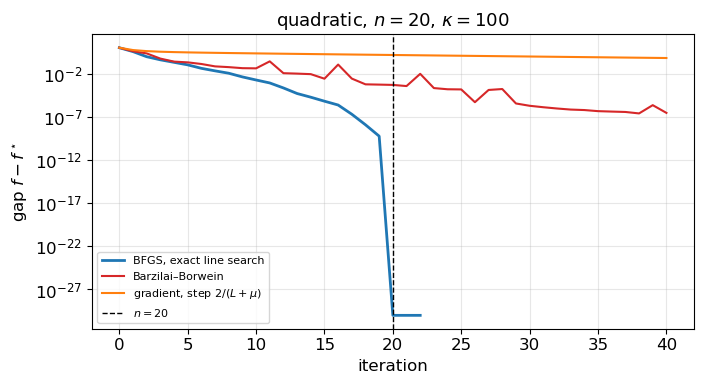

BFGS quadratic: gap at step 20 is 2.214e-39, skips 0
gradient gap at step 20: 1.631e+00; at step 40: 7.266e-01
BB gap at step 40: 3.126e-07; iterations where the gap increases: [11, 16, 22, 27, 28, 39]
BFGS on Rosenbrock from (-1.2, 1): 27 iterations, skips 0, f=5.374e-30, x=[1. 1.]
Armijo on -gradient at [-1.04618885  1.01144356]: alpha=0.0625, y·s=-44.670, f from 4.877 to 2.087


In [11]:
def wolfe_search(fun, grad, x, direction, c1=1e-4, c2=0.1):
    # The search from lecture 7.
    value0 = fun(x)
    slope0 = float(np.dot(grad(x), direction))
    if slope0 >= 0.0:
        return 0.0

    def phi(a):
        return fun(x + a * direction)

    def slope(a):
        return float(np.dot(grad(x + a * direction), direction))

    def zoom(a_lo, a_hi):
        for _ in range(25):
            a = 0.5 * (a_lo + a_hi)
            if phi(a) > value0 + c1 * a * slope0 or phi(a) >= phi(a_lo):
                a_hi = a
            else:
                da = slope(a)
                if abs(da) <= -c2 * slope0:
                    return a
                if da * (a_hi - a_lo) >= 0.0:
                    a_hi = a_lo
                a_lo = a
        return 0.5 * (a_lo + a_hi)

    a_prev, phi_prev = 0.0, value0
    a = 1.0
    for i in range(25):
        phi_a = phi(a)
        if phi_a > value0 + c1 * a * slope0 or (i > 0 and phi_a >= phi_prev):
            return zoom(a_prev, a)
        da = slope(a)
        if abs(da) <= -c2 * slope0:
            return a
        if da >= 0.0:
            return zoom(a, a_prev)
        a_prev, phi_prev = a, phi_a
        a *= 2.0
    return a_prev


def armijo_search(fun, grad, x, direction, c1=1e-4):
    slope0 = float(np.dot(grad(x), direction))
    if slope0 >= 0.0:
        return 0.0
    value0 = fun(x)
    a = 1.0
    for _ in range(40):
        if fun(x + a * direction) <= value0 + c1 * a * slope0:
            return a
        a *= 0.5
    return 0.0


def bfgs(fun, grad, x0, search, n_iter=80, grad_tol=1e-12):
    x = np.array(x0, dtype=float)
    n = len(x)
    W = np.eye(n)
    g = grad(x)
    gaps = [fun(x)]
    skips = 0
    for _ in range(n_iter):
        if np.dot(g, g) < grad_tol ** 2:
            break
        direction = -W @ g
        if float(np.dot(g, direction)) >= 0.0:
            direction = -g.copy()
            W = np.eye(n)
        alpha = search(fun, grad, x, direction)
        if alpha == 0.0:
            break
        s = alpha * direction
        x = x + s
        g_new = grad(x)
        y = g_new - g
        ys = float(np.dot(y, s))
        if ys > 1e-12 * np.linalg.norm(y) * np.linalg.norm(s):
            rho = 1.0 / ys
            V = np.eye(n) - rho * np.outer(s, y)
            W = V @ W @ V.T + rho * np.outer(s, s)
        else:
            skips += 1
        g = g_new
        gaps.append(fun(x))
    return np.array(gaps), skips, x


# A quadratic in its eigenbasis: f = (1/2) sum lambda_i x_i^2, minimizer 0.
rng = np.random.default_rng(0)
n_q, kappa_q = 20, 100.0
eigs_q = np.logspace(0.0, np.log10(kappa_q), n_q)
x0_q = rng.normal(size=n_q)
x0_q /= np.linalg.norm(x0_q)


def q_value(x):
    return 0.5 * float(np.sum(eigs_q * x * x))


def q_grad(x):
    return eigs_q * x


def exact_line_search(fun, grad, x, direction):
    # Closed form on this quadratic: alpha = -(g·d) / (d·H d).
    denom = float(np.dot(direction, eigs_q * direction))
    if denom <= 0.0:
        return 0.0
    return max(-float(np.dot(q_grad(x), direction)) / denom, 0.0)


bfgs_gaps, bfgs_skips, bfgs_x = bfgs(q_value, q_grad, x0_q, exact_line_search, n_iter=n_q + 2, grad_tol=0.0)

gd_x = x0_q.copy()
gd_gaps = [q_value(gd_x)]
eta_q = 2.0 / (eigs_q[-1] + eigs_q[0])
for _ in range(40):
    gd_x = gd_x - eta_q * q_grad(gd_x)
    gd_gaps.append(q_value(gd_x))
gd_gaps = np.array(gd_gaps)

bb_x = x0_q.copy()
bb_g = q_grad(bb_x)
bb_gaps = [q_value(bb_x)]
alpha_bb = 1.0 / eigs_q[-1]
for _ in range(40):
    bb_next = bb_x - alpha_bb * bb_g
    g_next = q_grad(bb_next)
    s = bb_next - bb_x
    y = g_next - bb_g
    sy = float(np.dot(s, y))
    if sy > 0.0:
        alpha_bb = float(np.dot(s, s)) / sy
    bb_x, bb_g = bb_next, g_next
    bb_gaps.append(q_value(bb_x))
bb_gaps = np.array(bb_gaps)

fig, ax = plt.subplots()
ax.semilogy(np.arange(len(bfgs_gaps)), np.maximum(bfgs_gaps, 1e-30), color="C0", lw=2, label="BFGS, exact line search")
ax.semilogy(np.arange(len(bb_gaps)), np.maximum(bb_gaps, 1e-30), color="C3", lw=1.5, label="Barzilai–Borwein")
ax.semilogy(np.arange(len(gd_gaps)), np.maximum(gd_gaps, 1e-30), color="C1", lw=1.5, label=r"gradient, step $2/(L+\mu)$")
ax.axvline(n_q, color="k", ls="--", lw=1, label=f"$n={n_q}$")
ax.set_xlabel("iteration")
ax.set_ylabel(r"gap $f-f^\star$")
ax.set_title(rf"quadratic, $n={n_q}$, $\kappa={kappa_q:.0f}$")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

rose_gaps, rose_skips, rose_x = bfgs(rosenbrock, rosenbrock_grad, np.array([-1.2, 1.0]), wolfe_search, n_iter=40)
print(f"BFGS quadratic: gap at step {n_q} is {bfgs_gaps[n_q]:.3e}, skips {bfgs_skips}")
print(f"gradient gap at step {n_q}: {gd_gaps[n_q]:.3e}; at step 40: {gd_gaps[40]:.3e}")
rises = np.where(np.diff(bb_gaps) > 0)[0] + 1
print(f"BB gap at step 40: {bb_gaps[40]:.3e}; iterations where the gap increases: {rises.tolist()}")
print(f"BFGS on Rosenbrock from (-1.2, 1): {len(rose_gaps) - 1} iterations, skips {rose_skips}, f={rose_gaps[-1]:.3e}, x={rose_x}")

# An Armijo step whose displacement has negative curvature against the gradient change.
curv_x = np.array([-1.04618885, 1.01144356])
curv_g = rosenbrock_grad(curv_x)
curv_d = -curv_g
curv_a = armijo_search(rosenbrock, rosenbrock_grad, curv_x, curv_d)
curv_s = curv_a * curv_d
curv_y = rosenbrock_grad(curv_x + curv_s) - curv_g
print(
    f"Armijo on -gradient at {curv_x}: alpha={curv_a:.4f}, "
    f"y·s={float(curv_y @ curv_s):.3f}, "
    f"f from {rosenbrock(curv_x):.3f} to {rosenbrock(curv_x + curv_s):.3f}"
)


## Reading BFGS and Barzilai–Borwein

- On the quadratic with $n=20$ and $\kappa=100$, BFGS with exact line search has gap $2.2\times 10^{-39}$ at iteration $20$. That is the finite termination: $n$ conjugate directions have been built, and the minimizer is in their span. The gradient iteration with step $2/(L+\mu)$ has gap $1.6$ at iteration $20$ and gap $0.72$ at iteration $40$, from a start at $11$.
- Barzilai–Borwein, on the same quadratic and the same start, reaches gap $3.1\times 10^{-7}$ at iteration $40$. The gap increases at iterations $11$, $16$, $22$, $27$, $28$ and $39$. Those rises are the bumps on the plot. There is no $n$-step zero. There is also no line search: an Armijo test would have rejected the rising steps, and the rejected lengths are part of how the Rayleigh quotient moves between the small and large eigenvalues.
- On Rosenbrock, from $(-1.2,\,1)$, BFGS with the Wolfe search reaches function value $5.4\times 10^{-30}$ in $27$ iterations, at the point $(1,1)$, with no skipped update. Wolfe kept $\mathbf{y}^{\!\top}\mathbf{s}>0$ on every step.
- The last print is a single Armijo step, on the negative gradient, at $(-1.046,\,1.011)$. The step is legal for Armijo: the function falls from $4.88$ to $2.09$, at length $\alpha=1/16$. The curvature product is $\mathbf{y}^{\!\top}\mathbf{s}=-44.7$. Feeding that pair to the BFGS formula would produce a matrix that is not positive definite. The skip rule exists for this step.


# 8. L-BFGS, when the matrix does not fit

- $W$ is dense even when $f''$ is sparse. At $n=10^5$ it does not fit, and the $O(n^2)$ product is more expensive than a gradient. L-BFGS stores the last $m$ pairs $(\mathbf{s}_i,\mathbf{y}_i)$ and nothing else. The usual range is $m$ between $5$ and $20$. Storage and the product both cost $O(mn)$.
- The operator applied to the gradient is the BFGS update of a scaled identity, using only those $m$ pairs. The scale is recomputed at every iteration from the newest pair,
$$
\gamma = \frac{\mathbf{s}^{\!\top}\mathbf{y}}{\mathbf{y}^{\!\top}\mathbf{y}}.
$$
This is the other Barzilai–Borwein quotient, $\min_\gamma \|\mathbf{s}-\gamma\mathbf{y}\|^2$. It estimates a step length along the most recent displacement, so the matrix that the $m$ updates correct is $\gamma I$ and the first step of a fresh run is a gradient step of that length.
- Discarding the pairs older than $m$ is the whole method. On a quadratic, BFGS needs every pair to build $n$ conjugate directions. A window of length $m<n$ has forgotten directions that were conjugate to the current one, and the $n$-step termination goes with them. Keeping all $n$ pairs brings the termination back, even though $\gamma$ is refreshed: the experiment below is that comparison.


## The two-loop product

- Pairs are kept oldest first. $\rho_i=1/(\mathbf{y}_i^{\!\top}\mathbf{s}_i)$. One vector $\mathbf{q}$ carries the product, so the $n\times n$ matrix is never formed.
- **First loop, newest pair down to oldest.** Start with $\mathbf{q}=f'(\mathbf{x})$. For each pair in that order set
$$
\alpha_i = \rho_i\,\mathbf{s}_i^{\!\top}\mathbf{q},
\qquad
\mathbf{q} \leftarrow \mathbf{q}-\alpha_i\mathbf{y}_i.
$$
This applies the right-hand factors $(I-\rho_i\mathbf{y}_i\mathbf{s}_i^{\!\top})$ and stores the coefficients $\alpha_i$ that the left-hand factors will need.
- **Scale.** Set $\mathbf{r}=\gamma\mathbf{q}$. This is the product with $\gamma I$, the matrix the updates are correcting.
- **Second loop, oldest pair up to newest.** For each pair,
$$
\beta = \rho_i\,\mathbf{y}_i^{\!\top}\mathbf{r},
\qquad
\mathbf{r} \leftarrow \mathbf{r}+\mathbf{s}_i(\alpha_i-\beta).
$$
This applies the left-hand factors $(I-\rho_i\mathbf{s}_i\mathbf{y}_i^{\!\top})$ and adds the rank-one term $\rho_i\mathbf{s}_i\mathbf{s}_i^{\!\top}$. The direction is $\mathbf{d}=-\mathbf{r}$.
- The two loops are the expanded form of
$$
W = \Big(\prod_{i=\mathrm{new}}^{\mathrm{old}}(I-\rho_i\mathbf{s}_i\mathbf{y}_i^{\!\top})\Big)(\gamma I)\Big(\prod_{i=\mathrm{old}}^{\mathrm{new}}(I-\rho_i\mathbf{y}_i\mathbf{s}_i^{\!\top})\Big)
$$
plus the rank-one terms picked up on the way out. Multiplying that expression by $f'(\mathbf{x})$ from the right is exactly the recursion above. The cost is $4m$ inner products of length $n$, independent of how large $n$ is except through the length of the vectors.


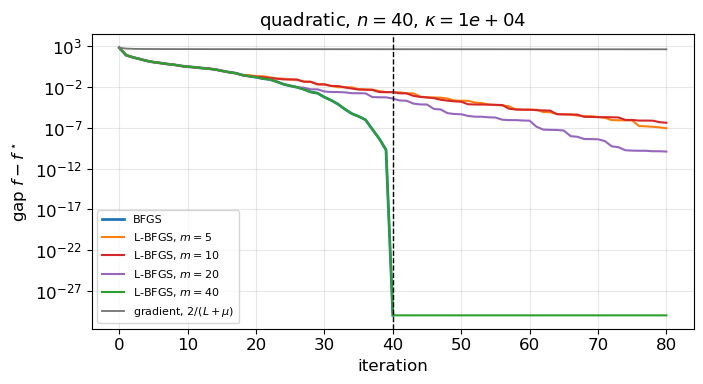

start gap 6.805e+02
BFGS at step 40: 4.772e-40
L-BFGS m= 5 at step 40: 2.389e-03, at step 80: 9.029e-08
L-BFGS m=10 at step 40: 2.383e-03, at step 80: 4.256e-07
L-BFGS m=20 at step 40: 3.963e-04, at step 80: 1.232e-10
L-BFGS m=40 at step 40: 8.676e-38, at step 80: 7.481e-104
gradient at step 40: 4.444e+02, at step 80: 4.356e+02


In [12]:
def lbfgs_direction(gradient, pairs, gamma):
    # pairs: oldest first, each entry is (s, y, rho). Two loops, one vector.
    q = gradient.copy()
    alphas = []
    for s, y, rho in reversed(pairs):
        alpha = rho * float(np.dot(s, q))
        alphas.append(alpha)
        q = q - alpha * y
    r = gamma * q
    for (s, y, rho), alpha in zip(pairs, reversed(alphas)):
        beta = rho * float(np.dot(y, r))
        r = r + s * (alpha - beta)
    return -r


def lbfgs_quadratic(memory, x0, n_iter):
    x = x0.copy()
    g = q_grad(x)
    pairs = []
    hist = [q_value(x)]
    for _ in range(n_iter):
        if pairs:
            s_last, y_last, _rho = pairs[-1]
            yy = float(np.dot(y_last, y_last))
            gamma = float(np.dot(s_last, y_last)) / yy
            direction = lbfgs_direction(g, pairs, gamma)
        else:
            direction = -g / eigs_l[-1]
        alpha = exact_line_search(q_value, q_grad, x, direction)
        if alpha == 0.0:
            break
        s = alpha * direction
        x = x + s
        g_new = q_grad(x)
        y = g_new - g
        ys = float(np.dot(y, s))
        if ys > 0.0:
            pairs.append((s, y, 1.0 / ys))
            if len(pairs) > memory:
                pairs.pop(0)
        g = g_new
        hist.append(q_value(x))
    return np.array(hist)


# A larger quadratic, so that forgetting pairs has somewhere to show.
rng_l = np.random.default_rng(0)
n_l, kappa_l = 40, 1.0e4
eigs_l = np.logspace(0.0, np.log10(kappa_l), n_l)
x0_l = rng_l.normal(size=n_l)
x0_l /= np.linalg.norm(x0_l)


def q_value(x, eigs=eigs_l):
    return 0.5 * float(np.sum(eigs * x * x))


def q_grad(x, eigs=eigs_l):
    return eigs * x


def exact_line_search(fun, grad, x, direction, eigs=eigs_l):
    denom = float(np.dot(direction, eigs * direction))
    if denom <= 0.0:
        return 0.0
    return max(-float(np.dot(eigs * x, direction)) / denom, 0.0)


def bfgs_quadratic_full(x0, n_iter):
    x = x0.copy()
    n = len(x)
    W = np.eye(n)
    g = q_grad(x)
    hist = [q_value(x)]
    for _ in range(n_iter):
        direction = -W @ g
        alpha = exact_line_search(None, None, x, direction)
        s = alpha * direction
        x = x + s
        g_new = q_grad(x)
        y = g_new - g
        ys = float(np.dot(y, s))
        rho = 1.0 / ys
        V = np.eye(n) - rho * np.outer(s, y)
        W = V @ W @ V.T + rho * np.outer(s, s)
        g = g_new
        hist.append(q_value(x))
    return np.array(hist)


full_hist = bfgs_quadratic_full(x0_l, n_l)
memories = {}
for m in (5, 10, 20, 40):
    memories[m] = lbfgs_quadratic(m, x0_l, 80)

gd_l = x0_l.copy()
gd_l_hist = [q_value(gd_l)]
eta_l = 2.0 / (eigs_l[-1] + eigs_l[0])
for _ in range(80):
    gd_l = gd_l - eta_l * q_grad(gd_l)
    gd_l_hist.append(q_value(gd_l))
gd_l_hist = np.array(gd_l_hist)

fig, ax = plt.subplots()
ax.semilogy(np.arange(len(full_hist)), np.maximum(full_hist, 1e-30), color="C0", lw=2.0, label="BFGS")
for m, color in ((5, "C1"), (10, "C3"), (20, "C4"), (40, "C2")):
    hist = memories[m]
    ax.semilogy(np.arange(len(hist)), np.maximum(hist, 1e-30), color=color, lw=1.5, label=f"L-BFGS, $m={m}$")
ax.semilogy(np.arange(len(gd_l_hist)), np.maximum(gd_l_hist, 1e-30), color="0.45", lw=1.3, label=r"gradient, $2/(L+\mu)$")
ax.axvline(n_l, color="k", ls="--", lw=1)
ax.set_xlabel("iteration")
ax.set_ylabel(r"gap $f-f^\star$")
ax.set_title(rf"quadratic, $n={n_l}$, $\kappa={kappa_l:.0e}$")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"start gap {full_hist[0]:.3e}")
print(f"BFGS at step {n_l}: {full_hist[n_l]:.3e}")
for m, hist in memories.items():
    print(f"L-BFGS m={m:2d} at step 40: {hist[40]:.3e}, at step 80: {hist[-1]:.3e}")
print(f"gradient at step 40: {gd_l_hist[40]:.3e}, at step 80: {gd_l_hist[80]:.3e}")


## Reading the memory

- The quadratic has $n=40$ and $\kappa=10^4$. The gap starts at $6.80\times 10^2$. BFGS reaches $4.8\times 10^{-40}$ at iteration $40$. That is the termination of section 7, at the dimension.
- L-BFGS with $m=40$ stores every pair this run produces, and it reaches $8.7\times 10^{-38}$ at iteration $40$. Refreshing the scale $\gamma$ did not remove the termination while every pair was still on hand.
- With $m=5$ the gap at iteration $40$ is $2.4\times 10^{-3}$, and at iteration $80$ it is $9.0\times 10^{-8}$. Memory $10$ is almost the same at iteration $40$, at $2.4\times 10^{-3}$. Memory $20$ is lower, at $4.0\times 10^{-4}$, and still many orders above the $m=40$ curve. The curves for $m=20$ and $m=40$ lie on top of each other until iteration $20$, which is the iteration at which $m=20$ drops its first pair. Forgetting starts there.
- The gradient iteration with step $2/(L+\mu)$ has gap $444$ at iteration $40$ and gap $436$ at iteration $80$. Limited memory is far ahead of that iteration, and with $m<n$ it does not reproduce the $n$-step zero. On a quadratic, conjugate gradients already has the zero, with three vectors. L-BFGS is the method for the case where $f$ is not quadratic and a Hessian-vector product is not the cheap operation.


# 9. What these methods are for

| | Newton | Damped Newton | Newton-CG | BFGS | L-BFGS | Barzilai–Borwein |
|---|---|---|---|---|---|---|
| What is stored | the Hessian, or its factor | the same | a few vectors | the dense inverse approximation | $m$ pairs $(\mathbf{s},\mathbf{y})$ | the previous point and gradient |
| Work per iteration | form and factor | form, factor, and a line search | a few Hessian-vector products | an $O(n^2)$ product and a Wolfe search | an $O(mn)$ product and a Wolfe search | one gradient |
| Local rate | quadratic | quadratic, once $\alpha=1$ is accepted | quadratic when $\eta=O(\|f'\|)$; linear when $\eta$ stays away from $0$ | superlinear on smooth strongly convex problems | the same theorem, with a shorter memory in practice | $R$-linear on quadratics |
| The hypothesis that fails first | a start outside the ball, or an indefinite Hessian | an indefinite Hessian with no fallback direction | a warm start, or a negative curvature the code does not stop on | $\mathbf{y}^{\!\top}\mathbf{s}\le 0$, which Armijo allows and Wolfe forbids | the same, plus a window too short for the spectrum | $\mathbf{s}^{\!\top}\mathbf{y}\le 0$ with no safeguard, or a line search that rejects the rise |

- Newton's advantage is the local rate. The $O(\log\log(1/\varepsilon))$ count describes the tail, after the iterate has entered the ball where $f''$ is Lipschitz and positive definite. Getting into that ball is the line search, or a start that is already there. Each iteration of the tail is a factorization.
- Damping does not give up the rate. It spends some early iterations at $\alpha<1$, and the tail is pure Newton. It cannot repair a direction that points uphill. That repair is a modified Hessian, or one gradient step, and during that iteration the quadratic model has been set aside.
- Newton-CG is the Newton method when the Hessian is only available as a product, or when the factor does not fit. The forcing term is the place the rate is chosen. A constant $\eta$ is a linear method with cheap steps. Driving $\eta$ down with the gradient restores the quadratic tail and spends the products on the last iterations, where they square the error.


## Quasi-Newton methods: what they buy, and where they stop

- BFGS is the default smooth unconstrained method at moderate $n$. It keeps a positive definite model of the inverse Hessian, the first step is a gradient step, and from then on the step is $\mathbf{d}=-Wf'(\mathbf{x})$ at $O(n^2)$. On a quadratic with exact line search it terminates in at most $n$ steps, as conjugate gradients does. On a smooth strongly convex function the convergence is superlinear. Superlinear is faster than the linear rate of gradient descent and slower than the quadratic rate of Newton: the log-log budget was paid for with a factorization, and BFGS does not do one.
- The Wolfe search is part of the method. It is what guarantees $\mathbf{y}^{\!\top}\mathbf{s}>0$, which is what keeps $W$ positive definite. Armijo can produce a step that decreases $f$ and has $\mathbf{y}^{\!\top}\mathbf{s}<0$. Skipping that update is correct. Skipping updates forever, because the search never looks at the new gradient, leaves the iteration at $W=I$, which is gradient descent.
- L-BFGS is the same update with a window. It runs at a cost comparable to a gradient when $m$ is small, and it is the method used when $n$ is large and there is no Hessian-vector product cheaper than a gradient. The two-loop recursion is the update, written so the matrix is never stored. On a quadratic the window is a loss: conjugate gradients, which keeps the whole Krylov subspace implicitly, finishes in at most $n$ steps, and L-BFGS with $m\ll n$ does not. The limited memory is for problems whose Hessian changes, so that a pair from many iterations ago describes a matrix the function no longer has.
- Barzilai–Borwein is the secant equation with a single degree of freedom. It often beats a fixed gradient step on a quadratic, and the gap is allowed to rise. It has no superlinear theorem and no $n$-step termination. It is the comparison to make when the alternative is gradient descent and a matrix, even a short one, is more than the problem should store.
- None of these replaces a Hessian that is genuinely cheap. A sparse factor, or a Hessian-vector product from the structure of the problem, is real curvature. Newton and Newton-CG use it. Quasi-Newton methods are the substitute for the situation in which that product is unavailable and the gradient is the oracle.


## Takeaway

- Newton's method minimizes the quadratic model whose curvature is $f''(\mathbf{x})$. The gradient step minimizes the same model with curvature $(1/\eta)I$. On a quadratic the Newton step reaches the minimizer in one iteration, at condition number $25$ and at condition number $10^6$.
- The same linear equation is Newton's method for a nonlinear system. For $z^3-1$ the basins of the three roots contain a neighborhood of each root, and the boundary of a basin is not a simple curve. The local theorem is the neighborhood.
- If $f''$ is Lipschitz and positive definite at the minimizer, the Newton error squares: $\|\mathbf{e}^+\|\le C\|\mathbf{e}\|^2$. On $f(t)=e^t-t$ the ratio $|t^+|/t^2$ converges to $1/2$. From $t=-4$ the same formula jumps to $t=49.6$ and increases the function by twenty-one orders of magnitude, because that start is outside every ball in which $f''$ is bounded below.
- Damped Newton accepts the unit step once the iterate is close, and the quadratic tail is the theorem of the undamped method. From $t=-4$ the unit step needs $55$ iterations to get under $10^{-12}$, and the damped iteration needs $6$. On Rosenbrock, a positive definite Hessian at $(-0.63,\,0.40)$ still sends the unit step from function value $2.66$ to $3.4\times 10^4$; Armijo takes $\alpha=1/16$ and the value falls. An indefinite Hessian at $(-0.865,\,0.754)$ makes the Newton direction uphill, with directional derivative $+21$, and the line search can only proceed after the direction is replaced.
- Inexact Newton lets conjugate gradients stop early. $\eta=0.5$ gave a linear outer decay in $43$ Hessian-vector products. $\eta_k=\min(0.5,\|f'\|)$ recovered the quadratic outer decay, with the product count growing from $4$ to $44$ as the gradient fell. The finite-difference product is most accurate near $\varepsilon=10^{-5}$ on the product tested here; $\varepsilon=10^{-1}$ and $\varepsilon=10^{-12}$ both sit near relative error $10^{-3}$.
- BFGS enforces the secant $W\mathbf{y}=\mathbf{s}$ by a rank-two update, stays positive definite when $\mathbf{y}^{\!\top}\mathbf{s}>0$, and the Wolfe search is what produces that inequality. On a quadratic it terminated at iteration $n$. Barzilai–Borwein fits the same secant with one scalar and is allowed to increase the gap.
- L-BFGS stores $m$ pairs and applies them with the two-loop recursion, at $O(mn)$. With $m=n$ the quadratic termination survived. With $m=5$ the gap at iteration $n$ was $2\times 10^{-3}$ rather than $10^{-37}$.


### References

- **Newton's method and quadratic convergence.** J. Nocedal and S. J. Wright, *Numerical Optimization*, Springer, 2006, Chapter 3. Theorem 3.5 is the quadratic rate under a Lipschitz Hessian, and the integral form of the remainder is the argument in that proof. Theorem 3.6 is the eventual acceptance of the unit step under Armijo.
- **The root-finding form, and the basins.** The iteration for a nonlinear system is the same chapter. The cubic $z^3-1$ and the geometry of its Newton basins go back to A. Cayley, *The Newton–Fourier imaginary problem*, American Journal of Mathematics, 2(1):97, 1879. The picture is the modern rendering of that problem.
- **Inexact Newton.** R. S. Dembo, S. C. Eisenstat, and T. Steihaug, *Inexact Newton methods*, SIAM Journal on Numerical Analysis, 19(2):400–408, 1982. The three regimes of the forcing term are their theorem. The conjugate-gradient truncation, including the negative-curvature exit and the start at $\mathbf{d}=\mathbf{0}$, is Nocedal and Wright, Algorithm 7.1.
- **BFGS.** C. G. Broyden, *The convergence of a class of double-rank minimization algorithms*, Journal of the Institute of Mathematics and Its Applications, 6(1):76–90, 1970; R. Fletcher, *A new approach to variable metric algorithms*, The Computer Journal, 13(3):317–322, 1970; D. Goldfarb, *A family of variable-metric methods derived by variational means*, Mathematics of Computation, 24(109):23–26, 1970; D. F. Shanno, *Conditioning of quasi-Newton methods for function minimization*, Mathematics of Computation, 24(111):647–656, 1970. The positive-definiteness argument, the secant check, and the $n$-step termination on quadratics with exact line search are Nocedal and Wright, Chapter 6.
- **The line search BFGS requires.** Nocedal and Wright, Chapter 3, for the Wolfe conditions, and lecture 7 of this course for the implementation. P. Wolfe, *Convergence conditions for ascent methods*, SIAM Review, 11(2):226–235, 1969.
- **Barzilai–Borwein.** J. Barzilai and J. M. Borwein, *Two-point step size gradient methods*, IMA Journal of Numerical Analysis, 8(1):141–148, 1988. The two quotients $\mathbf{s}^{\!\top}\mathbf{s}/\mathbf{s}^{\!\top}\mathbf{y}$ and $\mathbf{s}^{\!\top}\mathbf{y}/\mathbf{y}^{\!\top}\mathbf{y}$ are the least-squares fits in that paper. The second one is the L-BFGS scale $\gamma$.
- **L-BFGS.** J. Nocedal, *Updating quasi-Newton matrices with limited storage*, Mathematics of Computation, 35(151):773–782, 1980. D. C. Liu and J. Nocedal, *On the limited memory BFGS method for large scale optimization*, Mathematical Programming, 45:503–528, 1989. The two-loop recursion is Nocedal and Wright, Algorithm 7.4.
